In [2]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import time
from torch.utils.data import DataLoader, Subset
from torchvision.models import resnet18, ResNet18_Weights

torch.set_num_threads(2)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)

BATCH_SIZE  = 64
EPOCHS      = 2
NUM_CLASSES = 101
IMG_SIZE    = 224
TRAIN_SIZE  = 5000
TEST_SIZE   = 1000


imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

In [3]:
def load_data():
    mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=10),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ])
    test_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ])

    # Загружаем полные датасеты
    full_train = torchvision.datasets.Food101('./data', split='train', download=True, transform=train_transform)
    full_test = torchvision.datasets.Food101('./data', split='test', download=True, transform=test_transform)
    
    train_indices = list(range(min(TRAIN_SIZE, len(full_train))))
    test_indices = list(range(min(TEST_SIZE, len(full_test))))
 
    train_subset = Subset(full_train, train_indices)
    test_subset = Subset(full_test, test_indices)
    
    train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    return train_loader, test_loader, full_train.classes

train_loader, test_loader, CLASS_NAMES = load_data()

In [4]:
class ResNetClassifier(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

        # разморозка только последнего слоя и fc
        # for p in self.model.parameters():
        #     p.requires_grad = False

        # for p in self.model.layer4.parameters():
        #     p.requires_grad = True

        self.model.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.model(x)

def create_model():
    return ResNetClassifier().to(device)

model = create_model()


In [5]:
print(model)

ResNetClassifier(
  (model): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, tr

In [5]:
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f'Всего параметров:  {total:,}')
print(f'Обучаемых:         {trainable:,} ({100*trainable/total:.1f}%)')
print(f'Классификатор: {model.model.fc}')

Всего параметров:  11,333,797
Обучаемых:         11,333,797 (100.0%)
Классификатор: Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=512, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=101, bias=True)
)


In [6]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct    += outputs.max(1)[1].eq(labels).sum().item()
        total      += labels.size(0)
    return total_loss / total, correct / total


def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct    += outputs.max(1)[1].eq(labels).sum().item()
            total      += labels.size(0)
    return total_loss / total, correct / total




criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam([
    {'params': model.model.layer4.parameters(), 'lr': 1e-4},
    {'params': model.model.fc.parameters(),     'lr': 1e-3}], weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}
print(f"{'Эпоха':>6} | {'Train Loss':>10} | {'Test Loss':>9} | {'Train Acc':>9} | {'Test Acc':>9}")

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer)
    te_loss, te_acc = evaluate(model,   test_loader,  criterion)
    scheduler.step(te_loss)

    history['train_loss'].append(tr_loss)
    history['test_loss'].append(te_loss)
    history['train_acc'].append(tr_acc)
    history['test_acc'].append(te_acc)

    print(f'{epoch:6d} | {tr_loss:10.4f} | {te_loss:9.4f} | '
          f'{tr_acc*100:9.2f}% | {te_acc*100:9.2f}%  ({time.time()-t0:.0f}s)')


 Эпоха | Train Loss | Test Loss | Train Acc |  Test Acc
     1 |     0.8177 |    0.2064 |     75.24% |     93.10%  (839s)
     2 |     0.2901 |    0.1285 |     90.78% |     95.80%  (814s)


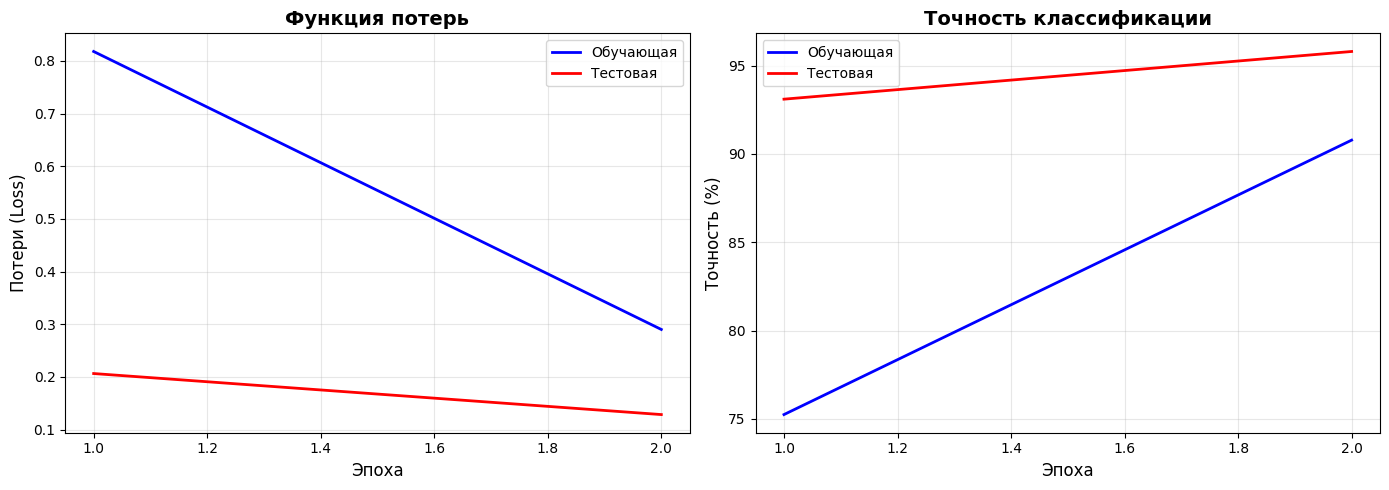

In [7]:
def plot_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    epochs = range(1, len(history['train_loss']) + 1)

    ax1.plot(epochs, history['train_loss'], 'b-', label='Обучающая', linewidth=2)
    ax1.plot(epochs, history['test_loss'],  'r-', label='Тестовая',  linewidth=2)
    ax1.set_xlabel('Эпоха', fontsize=12)
    ax1.set_ylabel('Потери (Loss)', fontsize=12)
    ax1.set_title('Функция потерь', fontsize=14, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3)

    ax2.plot(epochs, [a * 100 for a in history['train_acc']], 'b-', label='Обучающая', linewidth=2)
    ax2.plot(epochs, [a * 100 for a in history['test_acc']],  'r-', label='Тестовая',  linewidth=2)
    ax2.set_xlabel('Эпоха', fontsize=12)
    ax2.set_ylabel('Точность (%)', fontsize=12)
    ax2.set_title('Точность классификации', fontsize=14, fontweight='bold')
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('training_curves_food101.png', dpi=150, bbox_inches='tight')
    plt.show()

plot_history(history)

  Train — Loss: 0.1528  Accuracy: 95.08%
  Test  — Loss: 0.1285  Accuracy: 95.80%


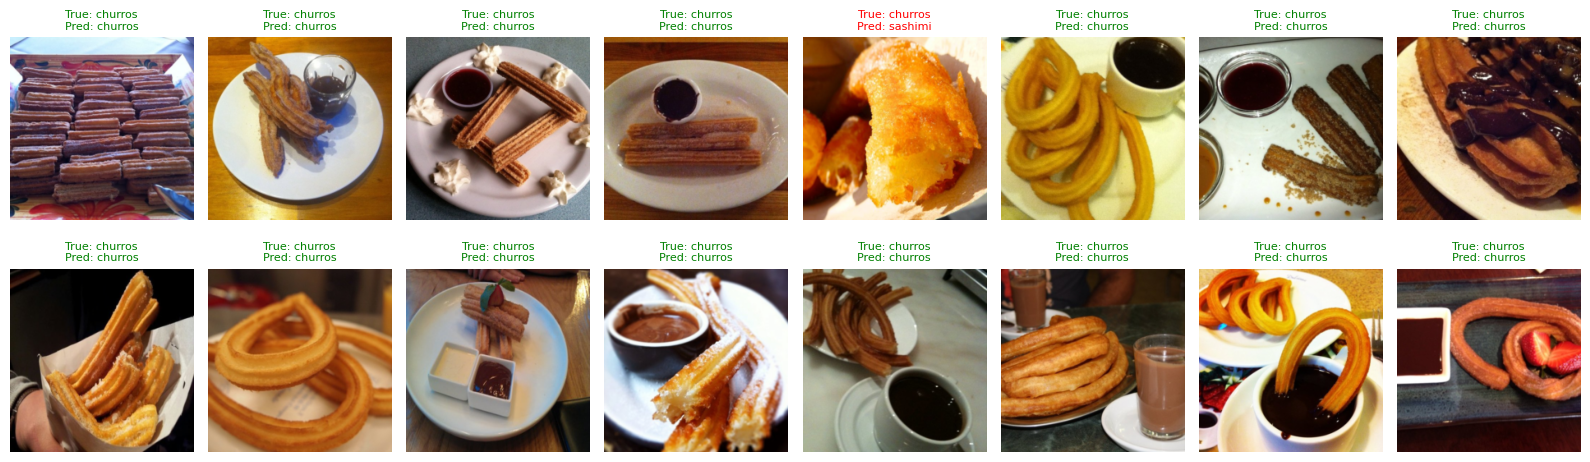

In [8]:
tr_loss, tr_acc = evaluate(model, train_loader, criterion)
te_loss, te_acc = evaluate(model, test_loader,  criterion)

print(f'  Train — Loss: {tr_loss:.4f}  Accuracy: {tr_acc*100:.2f}%')
print(f'  Test  — Loss: {te_loss:.4f}  Accuracy: {te_acc*100:.2f}%')


def imshow_predict(t):
    img = t.numpy().transpose(1, 2, 0)
    img = np.array(imagenet_std) * img + np.array(imagenet_mean)
    plt.imshow(np.clip(img, 0, 1))

model.eval()
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    outputs = model(images)
    _, predicted = outputs.max(1)

images = images.cpu()
labels = labels.cpu()
predicted = predicted.cpu()

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for i, ax in enumerate(axes.flat):
    if i >= len(images):
        break
    ax.axis('off')
    plt.sca(ax)
    imshow_predict(images[i])
    true_label = CLASS_NAMES[labels[i]].split('/')[-1] if hasattr(CLASS_NAMES[labels[i]], 'split') else str(labels[i])
    pred_label = CLASS_NAMES[predicted[i]].split('/')[-1] if hasattr(CLASS_NAMES[predicted[i]], 'split') else str(predicted[i])
    color = 'green' if predicted[i] == labels[i] else 'red'
    ax.set_title(f'True: {true_label}\nPred: {pred_label}', fontsize=8, color=color)
plt.tight_layout()
plt.show()